# 5. The multiscaling mechanism

Notebook 04 gave each life a volatility law $v^2\simeq V_F+B$: a fitness floor nearly independent of size plus a demographic
part that falls with size. This notebook shows that any law of that form fixes the whole spectrum $\zeta_q$, and that the
ratio curve bends below $q$ **if and only if the floor differs between firms of equal size**. On the network the floor grows
with the degree, and its heterogeneity predicts the measured bend; on a graph with equal degrees the ratios return close to $q$.

## An identity

Let a firm's squared volatility be a floor $u_i$ plus a part $B(\bar S)$ common to all firms of the same size, up to an
estimation factor $\epsilon_i$ independent of both: $v_i^2=(u_i+B(\bar S_i))\,\epsilon_i^2$. Let $b=-d\ln B/d\ln\bar S$ be the local
slope of the size-dependent part and $w=B/(u+B)$ its share of the variance. With $p(u\mid\bar S)$ the law of the floor at fixed
size and $E_q=\int p(u\mid\bar S)\,(u+B)^{q/2}du$, so that $\mathbb E[v^q\mid\bar S]=E_q\,\mathbb E[\epsilon^q]$, differentiating gives

$$\boxed{\zeta_q=-\frac{d\ln E_q}{d\ln\bar S}=\frac q2\,b\,\langle w\rangle_q-c_q,\qquad
\langle w\rangle_q=\frac{\mathbb E\big[(u+B)^{q/2}\,w\mid\bar S\big]}{\mathbb E\big[(u+B)^{q/2}\mid\bar S\big]},}$$

with a composition term $c_q=E_q^{-1}\int\partial_{\ln\bar S}p(u\mid\bar S)\,(u+B)^{q/2}du$ that vanishes if the law of the floor does not
depend on size. The exponent is the noise share weighted by $v^q$, times $b/2$: largest where noise dominates ($w\to1$), zero
where the floor does ($w\to0$).

## When the curve bends

With $Y=u+B$, $\langle w\rangle_q=B\,\mathbb E[Y^{q/2-1}]/\mathbb E[Y^{q/2}]=B\exp[h(q-2)-h(q)]$, where $h(q)=\ln\mathbb E[Y^{q/2}]$ is the
cumulant generating function of $\tfrac12\ln Y$, hence convex. Convexity makes $h(q)-h(q-2)$ non-decreasing, so $\langle w\rangle_q$ is
non-increasing in $q$, strictly unless $Y$ is degenerate at fixed size. Hence (for $c_q=0$)

$$\frac{\zeta_q}{\zeta_1}=q\,\frac{\langle w\rangle_q}{\langle w\rangle_1}\le q,$$

with equality iff the floor does not vary between firms of equal size. A floor that is the same for everybody, however it
depends on size, gives a volatility law of fixed shape and $\zeta_q=q\zeta_1$, like a granular model. The estimation factor
$\epsilon$ cancels in the ratios. If $\ln Y$ is Gaussian at fixed size with variance $s^2$, the bend is explicit:

$$\frac{\zeta_q}{\zeta_1}\simeq q\,e^{-(q-1)s^2/2},\qquad s^2=\operatorname{Var}\big(\ln(u+B)\mid\bar S\big)\simeq(1-w)^2\operatorname{Var}(\ln u\mid\bar S).$$

A heterogeneous floor bends the curve only where it is not small against the demographic part, so the bend is strongest at
large sizes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
import economy as eco
from economy import lives, FIGURES, MSB_RATIO, tidy

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})
QS = np.array([1, 2, 3, 4])

## The floor on the network

The volatility law gives every life (at least 20 growth rates) its own floor $V_F$, the growth variance of the noise-free
firm along the life's measured field. Replace $B$ by its mean in the life's size bin, $B(\bar S)$ (25 equal-count bins), so that
the floor is the only source of dispersion, and measure every quantity of the identity by fifths of size. Both reference
graphs: the power-law graph and a random regular graph with every degree equal to $C$ (the ablation), two economies each.

In [2]:
def binmean(x, P):
    y = np.empty_like(x)
    for p in P:
        y[p] = x[p].mean()
    return y


def zeta(Y, P, lx):
    return np.array([-np.polyfit(lx, np.log([np.mean(Y[p] ** (q / 2)) for p in P]), 1)[0] for q in QS])


def analyse(kind):
    Sb, vg, VF, B, deg = eco.decomposition(kind).T
    kap = deg / deg.mean()
    P = np.array_split(np.argsort(Sb), 25)
    lx = np.log([Sb[p].mean() for p in P])
    Bs, VFs = binmean(B, P), binmean(VF, P)
    out = {"zeta " + k: zeta(Y, P, lx) for k, Y in (("measured", vg), ("floor", VF + Bs), ("floor + noise", VF + B),
                                                    ("no floor spread", VFs + B))}
    F = [np.concatenate(P[i:i + 5]) for i in range(0, 25, 5)]
    fifths = lambda i: P[i:i + 5]
    b = np.array([-np.polyfit(lx[i:i + 5], np.log([B[p].mean() for p in fifths(i)]), 1)[0] for i in range(0, 25, 5)])
    w, Y = Bs / (VF + Bs), VF + Bs
    wq = np.array([[np.sum(w[p] * Y[p] ** (q / 2)) / np.sum(Y[p] ** (q / 2)) for q in QS] for p in F])
    s2 = np.array([np.mean([np.log(Y[p]).var() for p in fifths(i)]) for i in range(0, 25, 5)])
    w41 = np.array([np.mean([np.sum(w[p] * Y[p] ** 2) / np.sum(Y[p] ** 2) / (np.sum(w[p] * Y[p] ** 0.5) / np.sum(Y[p] ** 0.5))
                             for p in fifths(i)]) for i in range(0, 25, 5)])
    loc = np.array([[-np.polyfit(lx[i:i + 5], np.log([np.mean(Y[p] ** (q / 2)) for p in fifths(i)]), 1)[0] for q in QS]
                    for i in range(0, 25, 5)])
    out.update(Sb5=np.array([Sb[p].mean() for p in F]), kap5=np.array([kap[p].mean() for p in F]),
               var_lvf=np.array([np.log(VF[p]).var() for p in F]), b=b, wq=wq, s2=s2, w41=w41, loc=loc,
               ident=0.5 * QS[None, :] * b[:, None] * wq, meanVF=np.array([VF[p].mean() for p in F]), n=Sb.size)
    if kap.std() > 0.05:
        out["r2"] = np.array([np.corrcoef(np.log(VF[p]), np.log(kap[p]))[0, 1] ** 2 for p in F])
        out["h"] = np.polyfit(np.log(kap), np.log(VF), 1)[0]
        for j in (0, 4):
            p = F[j]
            e = np.quantile(kap[p], np.linspace(0, 1, 11))
            bi = np.clip(np.digitize(kap[p], e[1:-1]), 0, 9)
            out[f"vf_kappa_{j}"] = np.array([[np.median(kap[p][bi == k]), np.median(VF[p][bi == k])] for k in range(10)])
    return out


R = {k: analyse(k) for k in ("powerlaw", "regular")}
f5 = lambda a: " ".join(f"{x:5.2f}" for x in a)
for kind, r in R.items():
    print(f"=== {kind} graph: {r['n']} lives with >= 20 growth rates")
    for k in ("measured", "floor", "floor + noise", "no floor spread"):
        z = r["zeta " + k]
        print(f"  {k:16s} zeta {f5(z)}   ratios {f5(z[1:] / z[0])}")
    print(f"  by size fifth, Sbar               {f5(r['Sb5'])}")
    print(f"    mean relative degree            {f5(r['kap5'])}")
    print(f"    mean floor V_F                  {f5(r['meanVF'])}")
    print(f"    Var ln V_F                      {f5(r['var_lvf'])}")
    if "r2" in r:
        print(f"    share explained by ln kappa     {f5(r['r2'])}   (V_F ~ kappa^{r['h']:.2f} overall)")
    print(f"    slope b of B(Sbar)              {f5(r['b'])}")
    print(f"    noise share <w>_1               {f5(r['wq'][:, 0])}")
    print(f"    <w>_4/<w>_1                     {f5(r['wq'][:, 3] / r['wq'][:, 0])}")
    print(f"    s^2 within bins                 {' '.join(f'{x:.3f}' for x in r['s2'])}")
    print(f"    within-bin <w>_4/<w>_1          {f5(r['w41'])}   lognormal exp(-3 s^2/2): {f5(np.exp(-1.5 * r['s2']))}")
print("\nlocal zeta_q of 'floor' against (q/2) b <w>_q, power-law graph, by fifth:")
for i in range(5):
    print(f"  fifth {i + 1}: {f5(R['powerlaw']['loc'][i])}   vs   {f5(R['powerlaw']['ident'][i])}")

=== powerlaw graph: 197636 lives with >= 20 growth rates
  measured         zeta  0.19  0.33  0.44  0.52   ratios  1.77  2.35  2.78
  floor            zeta  0.23  0.44  0.60  0.73   ratios  1.86  2.57  3.10
  floor + noise    zeta  0.24  0.44  0.69  1.20   ratios  1.85  2.92  5.10
  no floor spread  zeta  0.21  0.44  0.76  1.37   ratios  2.08  3.64  6.55
  by size fifth, Sbar                0.36  0.72  1.09  1.58  2.86
    mean relative degree             0.76  0.82  0.89  1.01  1.51
    mean floor V_F                   0.11  0.13  0.13  0.13  0.13
    Var ln V_F                       0.50  0.45  0.50  0.59  0.85
    share explained by ln kappa      0.14  0.20  0.25  0.31  0.37   (V_F ~ kappa^0.70 overall)
    slope b of B(Sbar)               0.66  0.76  0.82  0.87  0.76
    noise share <w>_1                0.80  0.68  0.60  0.54  0.44
    <w>_4/<w>_1                      0.99  0.92  0.87  0.80  0.63
    s^2 within bins                 0.021 0.046 0.075 0.119 0.251
    within-bin <w>_4

Reading the output:

- **The floor is broad at fixed size, and the degree explains a growing share of it.** On the power-law graph
  $\operatorname{Var}(\ln V_F\mid\bar S)\approx0.5$ in the lower fifths, rising in the largest, with the share explained by the degree
  growing with size; overall $V_F\propto\kappa^{0.7}$.
- **The noise share falls with size, and its fall with $q$ grows with size**: $\langle w\rangle_4/\langle w\rangle_1$ drops from about
  $1$ to about $0.6$ across the fifths. The lognormal formula $e^{-3s^2/2}$ gives it to within $0.06$ on both graphs.
- **The identity holds** to about $10\%$ in the four lower fifths. In the largest, the composition term dominates: the largest
  lives also have the largest degrees, and the floor grows with the degree, so $c_q>0$.
- **The counterfactuals isolate the cause.** Own floor + bin-mean noise reproduces the bend (the floor is the only source of
  dispersion). Bin-mean floor + own noise puts the curve *above* $q$: without the spread of the floor, the per-life estimate of
  the demographic part has its own dispersion, largest among the smallest firms.
- **Ablation.** On the regular graph the floor still varies between lives, but it is small against the noise, so even the
  largest lives remain noise-dominated, $s^2$ stays small, and the ratio curve is close to $q$ (with a steeper $\zeta_1\approx0.4$).
  On the power-law graph the field amplitude of the larger, better connected firms keeps their floor up while their noise falls,
  and the spread of degrees spreads the floor: **degree heterogeneity is what bends the curve.**

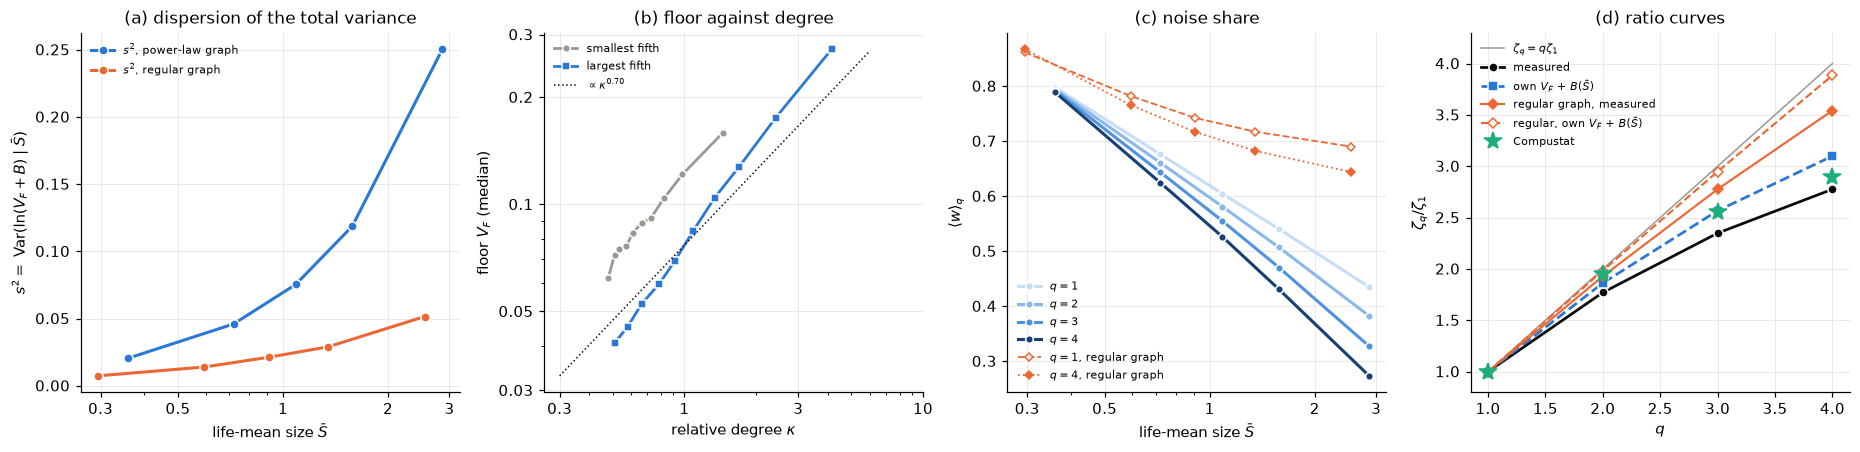

In [3]:
BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#9a9890", "#0b0b0b"
QCOL = ["#c7dcf5", "#8ab8ec", "#4f93e0", "#163f73"]
fig, axs = plt.subplots(1, 4, figsize=(17, 4.2))
a, b, c, d = axs
for kind, col, name in (("powerlaw", BLUE, "power-law graph"), ("regular", ORANGE, "regular graph")):
    a.plot(R[kind]["Sb5"], R[kind]["s2"], "o-", color=col, lw=2, ms=6, mec="white", label=rf"$s^2$, {name}")
a.set(xscale="log", xlabel=r"life-mean size $\bar S$", ylabel=r"$s^2=$ Var$(\ln(V_F+B)\mid\bar S)$", title="(a) dispersion of the total variance")
r = R["powerlaw"]
for j, mk, lab in ((0, "o", "smallest fifth"), (4, "s", "largest fifth")):
    x = r[f"vf_kappa_{j}"]
    b.loglog(x[:, 0], x[:, 1], mk + "-", color=BLUE if j else GREY, lw=1.8, ms=5, mec="white", label=lab)
kk = np.geomspace(0.3, 6, 10)
x4 = r["vf_kappa_4"]
b.loglog(kk, np.median(x4[:, 1]) * (kk / np.median(x4[:, 0])) ** r["h"], ":", color=INK, lw=1, label=rf"$\propto\kappa^{{{r['h']:.2f}}}$")
b.set(xlabel=r"relative degree $\kappa$", ylabel=r"floor $V_F$ (median)", title="(b) floor against degree")
for k, q in enumerate(QS):
    c.plot(r["Sb5"], r["wq"][:, k], "o-", color=QCOL[k], lw=2, ms=5, mec="white", label=rf"$q={q}$")
rr = R["regular"]
c.plot(rr["Sb5"], rr["wq"][:, 0], "D--", color=ORANGE, lw=1.2, ms=4, mfc="white", label=r"$q=1$, regular graph")
c.plot(rr["Sb5"], rr["wq"][:, 3], "D:", color=ORANGE, lw=1.2, ms=4, label=r"$q=4$, regular graph")
c.set(xscale="log", xlabel=r"life-mean size $\bar S$", ylabel=r"$\langle w\rangle_q$", title="(c) noise share")
d.plot(QS, QS, "-", color=GREY, lw=1, label=r"$\zeta_q=q\zeta_1$")
for key, col, mk, ls, lab in (("measured", INK, "o", "-", "measured"), ("floor", BLUE, "s", "--", r"own $V_F$ + $B(\bar S)$")):
    z = r[f"zeta {key}"]
    d.plot(QS, z / z[0], mk + ls, color=col, lw=1.8, ms=6, mec="white", label=lab)
for key, ls, lab in (("measured", "-", "regular graph, measured"), ("floor", "--", r"regular, own $V_F$ + $B(\bar S)$")):
    z = rr[f"zeta {key}"]
    d.plot(QS, z / z[0], "D" + ls, color=ORANGE, lw=1.4, ms=5, mfc="white" if ls == "--" else ORANGE, label=lab)
d.plot(QS, MSB_RATIO, "*", color="#1baf7a", ms=12, label="Compustat")
d.set(xlabel=r"$q$", ylabel=r"$\zeta_q/\zeta_1$", title="(d) ratio curves", ylim=(0.8, 4.3))
for ax in axs:
    tidy(ax, [0.3, 1, 3, 10] if ax is b else ([0.3, 0.5, 1, 2, 3] if ax.get_xscale() == "log" else None),
         [0.03, 0.05, 0.1, 0.2, 0.3] if ax.get_yscale() == "log" else None)
    ax.legend(frameon=False, fontsize=7.5)
plt.tight_layout()
plt.savefig(FIGURES / "demographic_multiscaling_law.png", dpi=200)

## A fitted floor

An alternative test, without the noise-free integration: fit $v^2=A\kappa^g+B_j$ (MAD volatility, one $B_j$ per size bin, common
$A$ and $g$) to the same kind of lives, read directly off the trajectories, and predict $\zeta_q$ from the fitted law averaged
over the degrees of the lives in each bin, times the empirical residual spread. The same law with every firm at the mean
degree gives exactly $\zeta_q=q\zeta_1$.

In [4]:
Sb, v, k = [], [], []
for seed in eco.SEEDS:
    d_ = np.load(eco.simulate_reference(seed))
    lv = [x for x in lives(d_["S"].astype(float), d_["L"]) if x[2] >= 20]
    Sb.append([x[0] for x in lv]); v.append([x[1] for x in lv]); k.append(d_["deg"][[x[5] for x in lv]])
Sb, v, k = (np.concatenate(x).astype(float) for x in (Sb, v, k))
kap = k / k.mean()
P = np.array_split(np.argsort(Sb), 25)
lx = np.log([Sb[p].mean() for p in P])
bi = np.empty(Sb.size, int)
for j, p in enumerate(P):
    bi[p] = j
resid = lambda th: np.log(v ** 2) - np.log(np.exp(th[0]) * kap ** th[1] + np.exp(th[2:][bi]))
th0 = np.r_[np.log(np.mean(v ** 2) / 2), 1.0, np.log([np.mean(v[p] ** 2) / 2 for p in P])]
sol = optimize.least_squares(resid, th0)
A, g, Bj = np.exp(sol.x[0]), sol.x[1], np.exp(sol.x[2:])
eps = np.exp(resid(sol.x) / 2)
slope = lambda m: -np.polyfit(lx, np.log(m), 1)[0]
z_meas = np.array([slope([np.mean(v[p] ** q) for p in P]) for q in QS])
z_pred = np.array([slope([np.mean((A * kap[p] ** g + Bj[j]) ** (q / 2)) * np.mean(eps ** q) for j, p in enumerate(P)]) for q in QS])
z_hom = np.array([slope([(A + Bj[j]) ** (q / 2) * np.mean(eps ** q) for j in range(25)]) for q in QS])
print(f"{Sb.size} lives; fit v^2 = A kappa^g + B(Sbar): A = {A:.4f}, g = {g:.2f}, B from {Bj[0]:.3f} to {Bj[-1]:.4f}")
print(f"ratios measured {f5(z_meas[1:] / z_meas[0])};  fitted law {f5(z_pred[1:] / z_pred[0])};  "
      f"same law at the mean degree {f5(z_hom[1:] / z_hom[0])}")

197636 lives; fit v^2 = A kappa^g + B(Sbar): A = 0.0644, g = 1.00, B from 0.412 to 0.0000
ratios measured  1.80  2.42  2.88;  fitted law  1.86  2.56  3.06;  same law at the mean degree  2.00  3.00  4.00


The fitted law gives $g\approx1$ (floor $\propto$ degree, as the field amplitude $\propto\sqrt\kappa$ suggests) and predicts the bend. The
fit assigns all of the top bins' variance to the floor ($B_j\to0$), so its partition differs from the physical one above; the
conclusion is the same.

**Summary.** Granular models give a heterogeneous *size*-dependence but a homogeneous shape, hence $\zeta_q=q\zeta_1$.
Heterogeneous interactions give a heterogeneous floor, hence the bend. The identity does not depend on the network model and
suggests two tests on firm data: the dispersion of volatilities among firms of equal size should grow with size, with a
firm's exposure to others (customers, suppliers, competitors) explaining a growing share of it; and conditioning on that
exposure should move the ratio curve towards $q$.